[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB13b_heterogeneous_regions.ipynb)

# Day 2 · Chapter 5 · Notebook 13b — Regions are not all the same

So far every region had the same distance to the bifurcation $a$. Here the **myelin map** of NB12 sets $a$ region by
region, with one extra number. Look at whether the fit to the measured FC improves, whether a shuffled map does as
well, and which regions end up close to (or past) the bifurcation.

The notebook is shipped executed; running it again takes about 30 seconds.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
# Load the connectome, the measured FC and the myelin map; define the Hopf fit
from src import connectome, wholebrain
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]           # 1 = same pattern as the measured FC
myelin = np.loadtxt("../data/connectome/myelin_t1wt2w_schaefer_100.csv", comments="#")    # one value per region (NB12)
m = (myelin - myelin.mean()) / myelin.std()                        # standardised: 0 = average, ±1 = one standard deviation

def show_matrix(ax, M, title, labels_on=True):                    # FC matrix, regions grouped by network
    im = ax.imshow(M[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1); ax.set_title(title, fontsize=10)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS if labels_on else [], fontsize=7)
    return im

def model_fc(G, a, seeds=2):                                       # average FC of 2 x 20-minute Hopf runs (NB10)
    return np.mean([np.corrcoef(wholebrain.hopf_network(sc, G, a=a, T=1200, TR=2.0, seed=s)[1].T) for s in range(seeds)], 0)

def best_over_G(a, G_list=(1.0, 1.5, 2.0, 3.0, 4.0)):              # refit the coupling for every setting
    return max((similarity(model_fc(G, a), fc), G) for G in G_list)

## 1. One extra number, and a control

> **Gist.** Every region gets its own distance to the bifurcation, set by its myelin: $a_i = a_0 + \beta\, m_i$.
> $\beta = 0$ is the homogeneous model; $\beta>0$ puts **more-myelinated (sensory) regions closer to the bifurcation**.
> For each $\beta$ we refit the coupling $G$. Control: the same values **shuffled** among regions.

<details><summary>Details (for the curious)</summary>

$m_i$: myelin of region $i$, standardised (0 = average, ±1 = one standard deviation). $a_0=-0.1$ is the best
homogeneous distance. $G$ is chosen among 1, 1.5, 2, 3, 4 for every setting; each FC is the average of two 20-minute
runs. The shuffled maps keep the same set of values, hence the same spread across regions, but put them in the wrong
places (20 shuffles, each with its own refitted $G$).
</details>

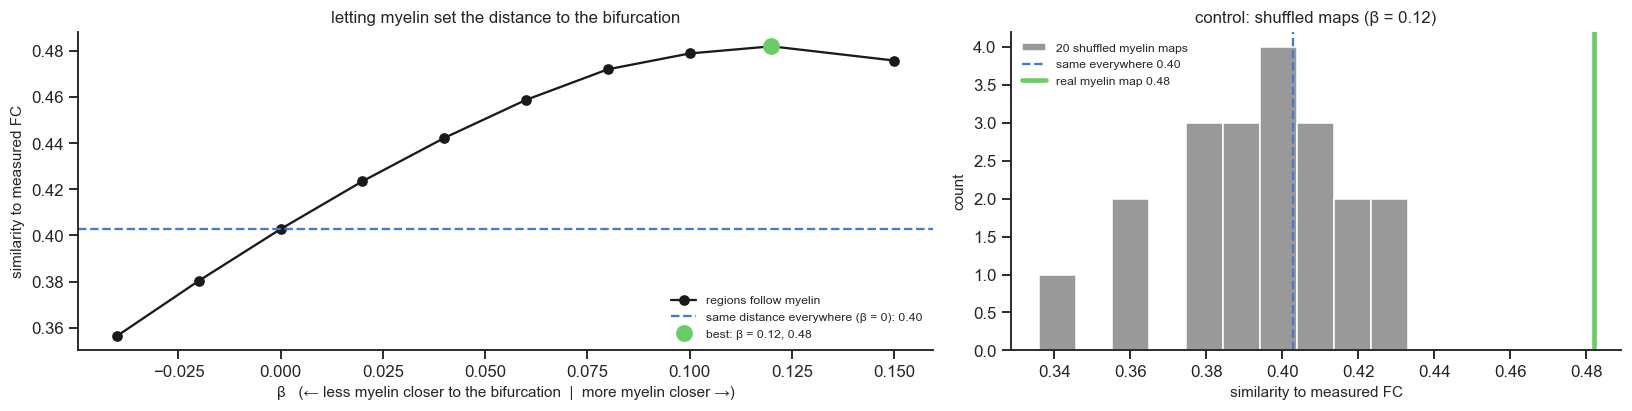

homogeneous: a = -0.1, G = 2.0: 0.40    myelin: beta = 0.12, G = 3.0: 0.48    shuffled: mean 0.40, best 0.43


In [2]:
# @title Scan beta, then the shuffled-map control (about 20 s)
a0 = -0.1
hom, G_hom = best_over_G(a0)
betas = np.r_[-0.04, -0.02, 0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.12, 0.15]
scan = [best_over_G(a0 + b * m) for b in betas]
fit = np.array([s[0] for s in scan])
b_best = betas[int(np.argmax(fit))]; het, G_het = scan[int(np.argmax(fit))]
rng = np.random.default_rng(0)
null = np.array([best_over_G(a0 + b_best * rng.permutation(m))[0] for _ in range(20)])

fig, ax = plt.subplots(1, 2, figsize=(15, 3.9), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].plot(betas, fit, "ko-", label="regions follow myelin")
ax[0].axhline(hom, c="C0", ls="--", label=f"same distance everywhere (β = 0): {hom:.2f}")
ax[0].plot(b_best, het, "o", c="C2", ms=10, label=f"best: β = {b_best}, {het:.2f}")
ax[0].set(xlabel="β   (← less myelin closer to the bifurcation  |  more myelin closer →)", ylabel="similarity to measured FC",
          title="letting myelin set the distance to the bifurcation"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].hist(null, bins=10, color="0.6", label="20 shuffled myelin maps")
ax[1].axvline(hom, c="C0", ls="--", label=f"same everywhere {hom:.2f}"); ax[1].axvline(het, c="C2", lw=3, label=f"real myelin map {het:.2f}")
ax[1].set(xlabel="similarity to measured FC", ylabel="count", title=f"control: shuffled maps (β = {b_best})"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"homogeneous: a = {a0}, G = {G_hom}: {hom:.2f}    myelin: beta = {b_best}, G = {G_het}: {het:.2f}    "
      f"shuffled: mean {null.mean():.2f}, best {null.max():.2f}")

**Left:** the fit improves steadily when sensory regions are closer to the bifurcation, and gets worse in the opposite
direction. **Right:** shuffled maps do no better than the homogeneous model. Making regions different at random does
not help; what helps is **where** the sensitive regions are.

## 2. What changes in the FC

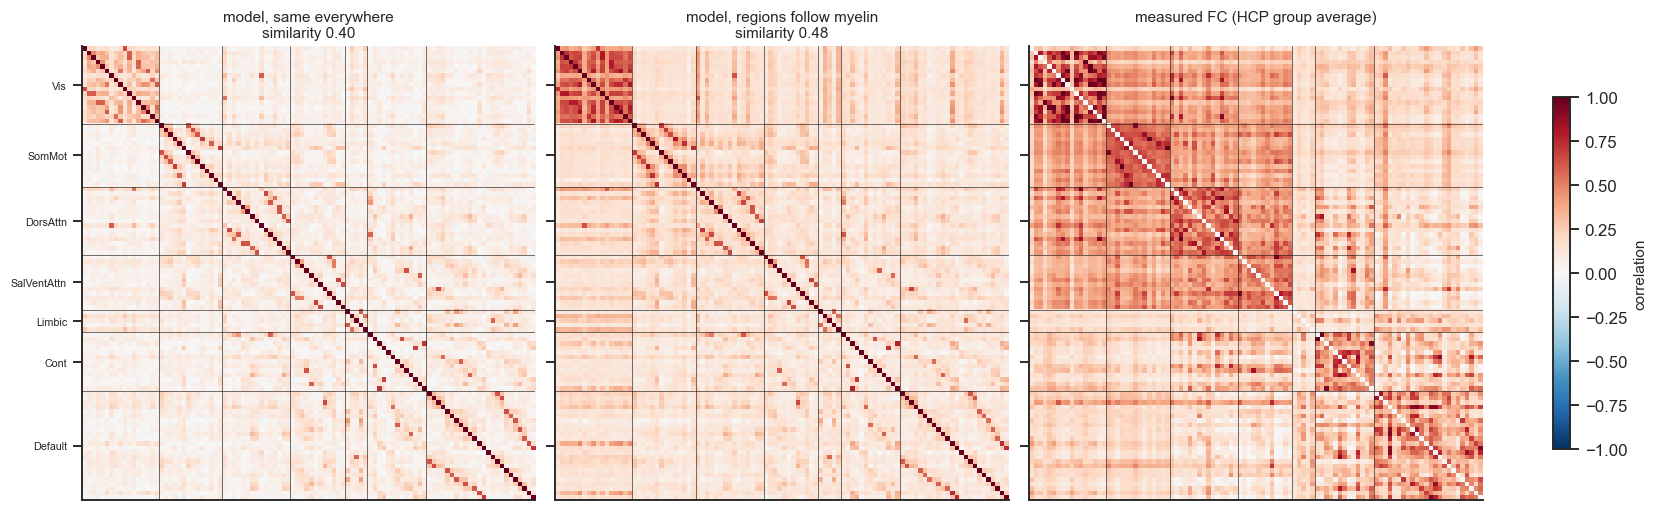

In [3]:
# @title Model FC (homogeneous and myelin-based) next to the measured FC
M_hom, M_het = model_fc(G_hom, a0), model_fc(G_het, a0 + b_best * m)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
show_matrix(ax[0], M_hom, f"model, same everywhere\nsimilarity {similarity(M_hom, fc):.2f}")
show_matrix(ax[1], M_het, f"model, regions follow myelin\nsimilarity {similarity(M_het, fc):.2f}", labels_on=False)
im = show_matrix(ax[2], fc, "measured FC (HCP group average)\n", labels_on=False)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlation")
plt.show()

With regions following myelin the visual block becomes much stronger, as in the measured FC. Both models still miss
much of the structure among association networks (control, default mode): there is room for more biology.

## 3. Where each region sits

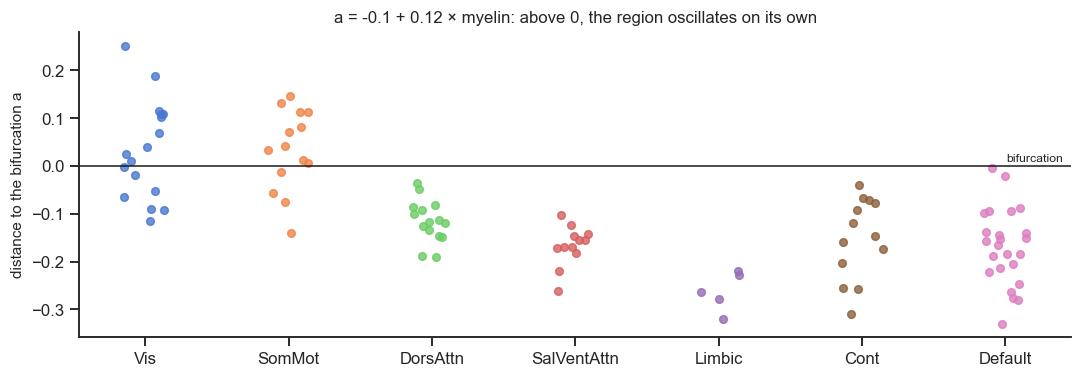

20 regions past the bifurcation: {'Vis': 10, 'SomMot': 10}


In [4]:
# @title Distance to the bifurcation of every region at the best setting, grouped by network
a = a0 + b_best * m
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, n in enumerate(NETS):
    v = a[net == n]; ax.plot(np.full(len(v), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), v, "o", c=f"C{k}", ms=5, alpha=0.8)
ax.axhline(0, c="k", lw=1); ax.text(len(NETS) - 0.6, 0.01, "bifurcation", fontsize=8, ha="right")
ax.set_xticks(range(len(NETS)), NETS)
ax.set(ylabel="distance to the bifurcation a", title=f"a = {a0} + {b_best} × myelin: above 0, the region oscillates on its own")
plt.tight_layout(); plt.show()
past = net[a > 0]
print(f"{len(past)} regions past the bifurcation:", {n: int((past == n).sum()) for n in NETS if (past == n).any()})

The most myelinated regions (20 in all, every one visual or somatomotor) sit **past** the bifurcation, slow
oscillators on their own; association regions are damped, well below it. Models with richer local dynamics, fitted region by region, reach the
same conclusion: local properties change along the cortical hierarchy (Demirtaş et al. 2019; Wang et al. 2019; Deco
et al. 2021).

## 4. Take-home

* A homogeneous model reproduces part of the measured FC (here 0.40).
* Letting intracortical myelin set each region's distance to the bifurcation improves the fit (0.48) with **one extra
  number**; shuffled maps do not (0.40 on average).
* What matters is **where** the sensitive regions are, along the sensory → association axis.

### Homework
*To do at home, after the class. These exercises need a few lines of your own code.*
1. **Other averages.** Repeat the β scan of section 1 with $a_0 = -0.05$ and $a_0 = -0.2$. Does the best β change?
2. **The FC gradient.** Use the principal FC gradient of NB12 instead of myelin. The fit improves even more. Why is this
   comparison less fair? (Hint: where does the gradient come from?)
3. **Only sensory regions.** Keep $a = a_0$ everywhere except the visual and somatomotor networks, where you set
   $a = 0$. How much of the improvement does this simple rule recover?

### References
* Glasser MF, Van Essen DC (2011). Mapping human cortical areas in vivo based on myelin content as revealed by T1- and
  T2-weighted MRI. *J Neurosci* 31:11597–11616.
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Demirtaş M et al. (2019). Hierarchical heterogeneity across human cortex shapes large-scale neural dynamics. *Neuron*
  101:1181–1194.
* Wang P et al. (2019). Inversion of a large-scale circuit model reveals a cortical hierarchy in the dynamic resting human
  brain. *Sci Adv* 5:eaat7854.
* Deco G et al. (2021). Dynamical consequences of regional heterogeneity in the brain's transcriptional landscape.
  *Sci Adv* 7:eabf4752.